<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/11-capstone/04_capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone: A Penguin Sexing Service, from Raw Records to an API

## The brief

Every breeding season, the Palmer Station field team measures the penguins in their study colonies. Knowing each bird's sex matters for almost every question they ask, but sexing penguins by eye is unreliable, and the reliable method needs a blood sample and a DNA test: more handling of the bird, lab costs, and weeks of waiting. Sometimes the test fails altogether.

The team asks for a tool that:

1. predicts a penguin's sex from its **species and four measurements** (bill length, bill depth, flipper length, body mass), which take a minute with callipers and a scale;
2. says **"unsure"** instead of guessing when the evidence is weak, because a wrong label is worse than no label;
3. works on **future seasons**, not just the ones it was trained on;
4. can be called by other software (a field tablet app, a spreadsheet macro) through a **web API**;
5. is documented well enough that someone else can judge whether to trust it.

You have the original data from three seasons (2007 to 2009), exactly as the researchers published it. This notebook goes from that raw file to a tested, running service, using everything in the course.

| Step | What | Course modules |
|---|---|---|
| 1 | Audit the raw data | 5, 7 |
| 2 | Clean and validate | 7, 10 |
| 3 | Decide which features the tool can use | 11 |
| 4 | Split by season | 9, 11 |
| 5 | Look at the training data | 8 |
| 6 | Compare models with cross-validation | 11 |
| 7 | Tune, and estimate honestly | 9, 11 |
| 8 | Choose when to say "unsure" | 9, 11 |
| 9 | Test on the new season, once | 9 |
| 10 | Check for drift | 11 |
| 11 | Save the model bundle and write a model card | 10, 11 |
| 12 | Build and test the API | 10, 11 |
| 13 | Run it for real | 11 |

## Setup

In [1]:
import importlib.util

missing = [pkg for pkg in ["fastapi", "httpx", "uvicorn"] if importlib.util.find_spec(pkg) is None]
if missing:
    packages = " ".join(missing)
    %pip install -q {packages}

In [2]:
import json
import re
import shutil
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/11-capstone/data/penguins_raw.csv"
local = Path("data/penguins_raw.csv")
SOURCE = local if local.exists() else DATA_URL

CAPSTONE = Path("work/capstone")
if CAPSTONE.exists():
    shutil.rmtree(CAPSTONE)
(CAPSTONE / "model").mkdir(parents=True)
(CAPSTONE / "tests").mkdir()
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.5


In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## Step 1: Audit the raw data

Before changing anything, look at what's actually there. The aim of an audit is a list of facts and surprises, not a model.

In [4]:
raw = pd.read_csv(SOURCE)
print(raw.shape)
raw.head(3).T

(344, 17)


,0,1,2
studyName,PAL0708,PAL0708,PAL0708
Sample Number,1,2,3
Species,Adelie Penguin (Pygoscelis adeliae),Adelie Penguin (Pygoscelis adeliae),Adelie Penguin (Pygoscelis adeliae)
Region,Anvers,Anvers,Anvers
Island,Torgersen,Torgersen,Torgersen
Stage,"Adult, 1 Egg Stage","Adult, 1 Egg Stage","Adult, 1 Egg Stage"
Individual ID,N1A1,N1A2,N2A1
Clutch Completion,Yes,Yes,Yes
Date Egg,2007-11-11,2007-11-11,2007-11-16
Culmen Length (mm),39.1,39.5,40.3


In [5]:
for column in ["studyName", "Species", "Region", "Island", "Stage", "Clutch Completion", "Sex"]:
    print(f"{column}: {raw[column].value_counts(dropna=False).to_dict()}")

studyName: {'PAL0910': 120, 'PAL0809': 114, 'PAL0708': 110}
Species: {'Adelie Penguin (Pygoscelis adeliae)': 152, 'Gentoo penguin (Pygoscelis papua)': 124, 'Chinstrap penguin (Pygoscelis antarctica)': 68}
Region: {'Anvers': 344}
Island: {'Biscoe': 168, 'Dream': 124, 'Torgersen': 52}
Stage: {'Adult, 1 Egg Stage': 344}
Clutch Completion: {'Yes': 308, 'No': 36}
Sex: {'MALE': 168, 'FEMALE': 165, nan: 11}


In [6]:
missing = raw.isna().sum()
print("missing values per column:")
print(missing[missing > 0].to_string())
print("\nmost common comments:")
print(raw["Comments"].value_counts().head(6).to_string())

missing values per column:
Culmen Length (mm)       2
Culmen Depth (mm)        2
Flipper Length (mm)      2
Body Mass (g)            2
Sex                     11
Delta 15 N (o/oo)       14
Delta 13 C (o/oo)       13
Comments               290

most common comments:
Comments
Nest never observed with full clutch.    34
Not enough blood for isotopes.            7
Sexing primers did not amplify.           4
No blood sample obtained.                 2
No blood sample obtained for sexing.      2
Adult not sampled.                        1


What the audit shows:

- **344 birds, 17 columns**, from three seasons (`PAL0708`, `PAL0809`, `PAL0910`, meaning 2007/08 to 2009/10).
- **Long, inconsistent names.** Columns like `Culmen Length (mm)` ("culmen" is the bird's word for the top ridge of the bill), and species recorded as `"Adelie Penguin (Pygoscelis adeliae)"` but `"Gentoo penguin (Pygoscelis papua)"`, with a different capital letter.
- **Constant columns.** `Region` and `Stage` have one value each, so they carry no information.
- **11 birds have no sex recorded**, and 2 have no measurements at all.
- **The isotope columns** (`Delta 15 N`, `Delta 13 C`, chemical signatures of diet measured from blood) are missing for 13 to 14 birds, often with the comment *"Not enough blood for isotopes"*.
- **Comments explain gaps**: failed sexing tests, no blood sample, nests never seen with a full clutch.

One more column needs checking: `Individual ID` looks like an identifier for each bird, and if the same bird appears in several seasons, a season-based split could see it on both sides.

In [7]:
key = raw["Species"].str.split().str[0] + "/" + raw["Island"] + "/" + raw["Individual ID"]
repeats = raw.assign(key=key)[key.duplicated(keep=False)].sort_values(["key", "studyName"])
print(f"{key.nunique()} distinct species/island/ID combinations for {len(raw)} rows")
repeats[["key", "studyName", "Sex", "Culmen Length (mm)", "Flipper Length (mm)", "Body Mass (g)"]].head(6)

304 distinct species/island/ID combinations for 344 rows


,key,studyName,Sex,Culmen Length (mm),Flipper Length (mm),Body Mass (g)
276,Chinstrap/Dream/N61A1,PAL0708,FEMALE,46.5,192.0,3500.0
302,Chinstrap/Dream/N61A1,PAL0809,FEMALE,50.5,200.0,3400.0
277,Chinstrap/Dream/N61A2,PAL0708,MALE,50.0,196.0,3900.0
303,Chinstrap/Dream/N61A2,PAL0809,MALE,49.5,200.0,3800.0
278,Chinstrap/Dream/N62A1,PAL0708,MALE,51.3,193.0,3650.0
304,Chinstrap/Dream/N62A1,PAL0809,FEMALE,46.4,191.0,3700.0


Some IDs do repeat across seasons, but look at the rows: the "same" bird has a different bill length, a different flipper length, and sometimes a **different sex**. Adult penguins don't change sex or shrink their bills between seasons. These IDs label **nest positions** (N61A1 is nest 61, adult 1), and nest numbers are reused from year to year.

So `Individual ID` can't be used to group repeat measurements of a bird, and the data gives no way to tell whether a bird was measured twice. That's worth writing down as a known limitation rather than ignoring: if some birds do appear in more than one season, test scores could be slightly optimistic.

## Step 2: Clean and validate

The cleaning functions are the ones from the exercises. Each step is small and checkable, and the result is a tidy table with clear names and types.

In [8]:
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
MEASUREMENTS = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
SEASONS = {"PAL0708": 2007, "PAL0809": 2008, "PAL0910": 2009}


def snake_case(name: str) -> str:
    name = re.sub(r"([a-z0-9])([A-Z])", r"\1_\2", name)
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_").lower()


def clean_species(series: pd.Series) -> pd.Series:
    if series.isna().any():
        raise ValueError(f"{series.isna().sum()} missing species values")
    first_word = series.astype(str).str.strip().str.split().str[0].str.capitalize()
    bad = sorted(set(series[~first_word.isin(SPECIES)]))
    if bad:
        raise ValueError(f"unknown species: {bad}")
    return first_word


def clean_sex(series: pd.Series) -> pd.Series:
    cleaned = series.str.strip().str.lower()
    return cleaned.where(cleaned.isin(["male", "female"]))


def clean(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.rename(columns=snake_case)
    season = df["study_name"].map(SEASONS)
    if season.isna().any():
        raise ValueError(f"unknown study names: {sorted(set(df.loc[season.isna(), 'study_name']))}")
    return pd.DataFrame({
        "season": season.astype(int),
        "species": clean_species(df["species"]),
        "island": df["island"],
        "sex": clean_sex(df["sex"]),
        "bill_length_mm": df["culmen_length_mm"],
        "bill_depth_mm": df["culmen_depth_mm"],
        "flipper_length_mm": df["flipper_length_mm"],
        "body_mass_g": df["body_mass_g"],
        "delta_15n": df["delta_15_n_o_oo"],
        "delta_13c": df["delta_13_c_o_oo"],
        "clutch_complete": df["clutch_completion"].map({"Yes": True, "No": False}),
        "comments": df["comments"],
    })


penguins = clean(raw)
penguins.head()

,season,species,island,sex,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,delta_15n,delta_13c,clutch_complete,comments
0,2007,Adelie,Torgersen,male,39.1,18.7,181.0,3750.0,NaN,NaN,True,Not enough blood for isotopes.
1,2007,Adelie,Torgersen,female,39.5,17.4,186.0,3800.0,8.94956,-24.69454,True,NaN
2,2007,Adelie,Torgersen,female,40.3,18.0,195.0,3250.0,8.36821,-25.33302,True,NaN
3,2007,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,Adult not sampled.
4,2007,Adelie,Torgersen,female,36.7,19.3,193.0,3450.0,8.76651,-25.32426,True,NaN


Now validate. The limits are generous sanity bounds for adult penguins of these species; anything outside them would most likely be a unit or data-entry error.

In [9]:
LIMITS = {"bill_length_mm": (25, 70), "bill_depth_mm": (10, 25),
          "flipper_length_mm": (160, 240), "body_mass_g": (2000, 7000)}

problems = []
for column, (low, high) in LIMITS.items():
    bad = penguins[column].notna() & ~penguins[column].between(low, high)
    problems += [(row, column, value) for row, value in penguins.loc[bad, column].items()]
print("values outside plausible limits:", problems if problems else "none")
print("species counts:", penguins["species"].value_counts().to_dict())
print("sex counts:", penguins["sex"].value_counts(dropna=False).to_dict())

values outside plausible limits: none
species counts: {'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}
sex counts: {'male': 168, 'female': 165, nan: 11}


Nothing implausible. Now the rows the model can learn from: the ones with a known sex and all four measurements.

In [10]:
no_sex = penguins["sex"].isna()
no_measurements = penguins[MEASUREMENTS].isna().any(axis=1)
print(f"no sex recorded:         {no_sex.sum()}")
print(f"no measurements:         {no_measurements.sum()} (both also have no sex)")
print("\nwhy sex is missing:")
print(penguins.loc[no_sex, "comments"].fillna("(no comment)").value_counts().to_string())

labelled = penguins[~no_sex & ~no_measurements].reset_index(drop=True)
print(f"\nusable for training and testing: {len(labelled)} of {len(penguins)}")

no sex recorded:         11
no measurements:         2 (both also have no sex)

why sex is missing:
comments
Sexing primers did not amplify.                                   4
No blood sample obtained.                                         2
No blood sample obtained for sexing.                              2
Adult not sampled.                                                1
Sexing primers did not amplify. Not enough blood for isotopes.    1
Adult not sampled. Nest never observed with full clutch.          1

usable for training and testing: 333 of 344


The birds without a recorded sex are exactly the ones the brief is about: their DNA test failed, or no blood sample could be taken. They can't be used to train or test the model, but they're a reminder that the tool would be useful even for this study's own data.

## Step 3: Decide which features the tool can use

The raw data has more columns than the four measurements. Before trying them, ask the most important feature question: **will this information be available when the tool is used?**

| column | available in the field? | decision |
|---|---|---|
| species, four measurements | yes, in a minute | **use** |
| island | yes, but the tool should work for other colonies too, and island mostly repeats species | leave out |
| isotopes (δ15N, δ13C) | **no**: they need a blood sample and a lab, and with a blood sample you'd just do the DNA test | **must not use** |
| clutch completion | no: only known weeks later, at the end of the nesting season | **must not use** |

Isotopes are the instructive case. They might even help accuracy, and a model built only to win on the test set would include them. But a tool that needs a blood sample to avoid needing a blood sample is useless. For interest, Step 6 checks whether they would have helped anyway.

In [11]:
FEATURES = ["species"] + MEASUREMENTS

## Step 4: Split by season

The tool will be used on **future** seasons. So the honest test is to train on the past and test on a later season: train on 2007 and 2008, and hold out **2009** completely until Step 9. A random split would mix seasons, and couldn't reveal whether anything changes from year to year.

In [12]:
train = labelled[labelled["season"] < 2009].reset_index(drop=True)
test = labelled[labelled["season"] == 2009].reset_index(drop=True)
y_train = train["sex"].eq("male").astype(int)
y_test = test["sex"].eq("male").astype(int)

print(f"train (2007-2008): {len(train)} birds, {y_train.mean():.0%} male")
print(f"test  (2009):      {len(test)} birds, {y_test.mean():.0%} male")
print(pd.crosstab(labelled["season"], labelled["species"]))

train (2007-2008): 216 birds, 50% male
test  (2009):      117 birds, 50% male
species  Adelie  Chinstrap  Gentoo
season                            
2007         44         26      33
2008         50         18      45
2009         52         24      41


From here until Step 9, `test` isn't touched. Every choice (model, settings, the "unsure" rule) is made with cross-validation on the training seasons only.

## Step 5: Look at the training data

Module 9 found that body mass separates the sexes well **within** a species. Here's the training data, one panel per species, with the two measurements that carry most of the signal:

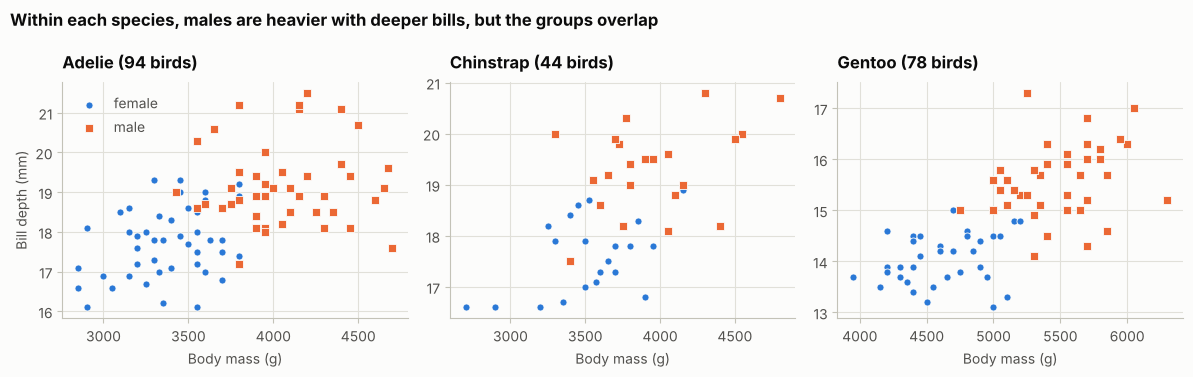

In [13]:
SEX_COLOURS = {"female": PALETTE[0], "male": PALETTE[1]}
SEX_MARKERS = {"female": "o", "male": "s"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, species in zip(axes, SPECIES):
    rows = train[train["species"] == species]
    for sex in ["female", "male"]:
        group = rows[rows["sex"] == sex]
        ax.scatter(group["body_mass_g"], group["bill_depth_mm"], color=SEX_COLOURS[sex], marker=SEX_MARKERS[sex],
                   s=26, edgecolors=SURFACE, linewidths=0.6, label=sex)
    ax.set_title(f"{species} ({len(rows)} birds)")
    ax.set_xlabel("Body mass (g)")
axes[0].set_ylabel("Bill depth (mm)")
axes[0].legend(loc="upper left")
fig.suptitle("Within each species, males are heavier with deeper bills, but the groups overlap",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Each species has its own scale (Gentoos are much heavier), and within each one males sit up and to the right. But in every panel there's a band where the two sexes overlap. No model can be certain about birds in that band, which is exactly why the brief asks for an "unsure" answer.

## Step 6: Compare models with cross-validation

Every candidate is a pipeline that takes the raw columns, so preprocessing happens inside each fold. All of them are scored on the same 10 stratified folds of the training seasons.

In [14]:
import warnings

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def preprocessor(numeric):
    return ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
        ("species", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["species"]),
    ])


ISOTOPES = ["delta_15n", "delta_13c"]
candidates = {
    "baseline (most common sex)": make_pipeline(preprocessor(MEASUREMENTS), DummyClassifier()),
    "logistic regression": make_pipeline(preprocessor(MEASUREMENTS), LogisticRegression(max_iter=1000)),
    "k-nearest neighbours (k=15)": make_pipeline(preprocessor(MEASUREMENTS), KNeighborsClassifier(n_neighbors=15)),
    "random forest": make_pipeline(preprocessor(MEASUREMENTS), RandomForestClassifier(n_estimators=300, random_state=0)),
    "gradient boosting": make_pipeline(preprocessor(MEASUREMENTS), HistGradientBoostingClassifier(random_state=0)),
    "logistic + isotopes (not usable)": make_pipeline(preprocessor(MEASUREMENTS + ISOTOPES), LogisticRegression(max_iter=1000)),
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
fold_scores = {name: cross_val_score(model, train, y_train, cv=cv) for name, model in candidates.items()}
comparison = pd.DataFrame({name: {"mean": s.mean(), "std": s.std()} for name, s in fold_scores.items()}).T
comparison.sort_values("mean", ascending=False).round(3)

,mean,std
k-nearest neighbours (k=15),0.935,0.043
logistic regression,0.931,0.043
logistic + isotopes (not usable),0.921,0.047
gradient boosting,0.917,0.057
random forest,0.912,0.052
baseline (most common sex),0.505,0.014


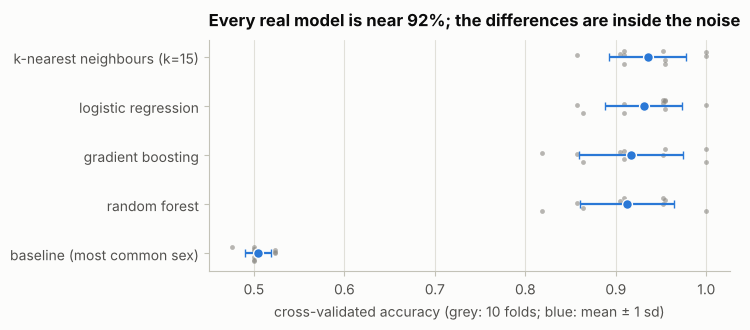

In [15]:
usable = [name for name in comparison.sort_values("mean").index if "not usable" not in name]
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, size=10)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for row, name in enumerate(usable):
    s = fold_scores[name]
    ax.scatter(s, row + jitter, color=MUTED, s=12, alpha=0.6, zorder=2)
    ax.errorbar(s.mean(), row, xerr=s.std(), color=PALETTE[0], capsize=3, zorder=3)
    ax.scatter([s.mean()], [row], color=PALETTE[0], s=50, zorder=4, edgecolors=SURFACE, linewidths=1)
ax.set_yticks(range(len(usable)), usable)
ax.grid(axis="y", visible=False)
ax.set_xlabel("cross-validated accuracy (grey: 10 folds; blue: mean ± 1 sd)")
ax.set_title("Every real model is near 92%; the differences are inside the noise")
fig.tight_layout()
plt.show()

What this says:

- **Every real model is far above the 50% baseline**, and all of them land within a couple of points of each other, around 91 to 93%.
- **The fold-to-fold spread is larger than the gaps between models.** k-nearest neighbours has the highest mean, but every other model is within one standard deviation of it.
- **The isotopes wouldn't have helped anyway.** Logistic regression with them scores no better than without.

When models are this close, choose by the other things that matter. **Logistic regression** is the choice here: its probabilities are smooth and meaningful (important for the "unsure" rule), it's fast, it can be explained to the field team with a table of weights, and it's the model you built by hand in Module 9, so you know exactly what it does.

## Step 7: Tune, and estimate honestly

Logistic regression has one important hyperparameter, the regularisation strength `C`. Tune it with a grid search, then use nested cross-validation (exercise 10) to estimate how well "logistic regression with tuned `C`" really does.

In [16]:
from sklearn.model_selection import GridSearchCV

pipeline = make_pipeline(preprocessor(MEASUREMENTS), LogisticRegression(max_iter=1000))
grid = {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}
search = GridSearchCV(pipeline, grid, cv=cv).fit(train, y_train)

results = pd.DataFrame(search.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]]
print(results.round(3).to_string(index=False))
print(f"\nbest: C = {search.best_params_['logisticregression__C']}, score {search.best_score_:.3f}")

 param_logisticregression__C  mean_test_score  std_test_score
                        0.01            0.847           0.072
                        0.10            0.930           0.048
                        1.00            0.931           0.043
                       10.00            0.931           0.043
                      100.00            0.931           0.043

best: C = 1, score 0.931


In [17]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
nested_scores, chosen = [], []
for tr, te in outer.split(train, y_train):
    inner_search = GridSearchCV(pipeline, grid, cv=StratifiedKFold(5, shuffle=True, random_state=2))
    inner_search.fit(train.iloc[tr], y_train.iloc[tr])
    nested_scores.append(inner_search.score(train.iloc[te], y_train.iloc[te]))
    chosen.append(inner_search.best_params_["logisticregression__C"])

print(f"best score inside the search: {search.best_score_:.3f}")
print(f"nested estimate:              {np.mean(nested_scores):.3f} ± {np.std(nested_scores):.3f}")
print("C chosen in each outer fold: ", chosen)

best score inside the search: 0.931
nested estimate:              0.917 ± 0.035
C chosen in each outer fold:  [1, 1, 1, 1, 100]


Two lessons in two cells:

- **The grid search's best score is optimistic.** It's the maximum of five noisy estimates. The nested estimate, where the choice of `C` is made without seeing the scoring fold, is lower. That lower number is the one to expect.
- **The search is choosing between ties.** Every `C` from 0.1 to 100 scores within a fraction of a point of the others; only very strong regularisation (`C = 0.01`) is clearly worse. `C = 1`, scikit-learn's default, won in most outer folds, but not all. The exact choice barely matters, and no one should read much into it.

In [18]:
model = search.best_estimator_            # refitted on all of the training seasons
C = search.best_params_["logisticregression__C"]
weights = pd.Series(model[-1].coef_[0], index=model[:-1].get_feature_names_out()).round(2)
print(f"final model: logistic regression, C = {C}")
print(weights.to_string())

final model: logistic regression, C = 1
numeric__bill_length_mm       1.34
numeric__bill_depth_mm        2.89
numeric__flipper_length_mm    0.23
numeric__body_mass_g          2.78
species__species_Adelie       1.33
species__species_Chinstrap   -1.01
species__species_Gentoo      -0.36


The weights tell the same story as Module 9: on standardised measurements, a heavier bird with a deeper, longer bill is more likely male. The species columns adjust the baseline for each species' size.

## Step 8: Choose when to say "unsure"

The tool abstains when the predicted probability is within a **margin** of 0.5. A wider margin means fewer answers, but more of them right. The margin must be chosen **without the test set**, so use **out-of-fold** predictions: `cross_val_predict` gives each training bird a probability from a model that didn't see it.

In [19]:
from sklearn.model_selection import cross_val_predict


def selective_accuracy(y_true, p, margin):
    y_true, p = np.asarray(y_true), np.asarray(p)
    covered = np.abs(p - 0.5) >= margin
    n = int(covered.sum())
    accuracy = float(((p[covered] >= 0.5) == y_true[covered]).mean()) if n else float("nan")
    return {"coverage": n / len(p), "accuracy": accuracy, "n_covered": n}


p_oof = cross_val_predict(model, train, y_train, cv=cv, method="predict_proba")[:, 1]
margins = np.round(np.arange(0, 0.46, 0.05), 2)
tradeoff = pd.DataFrame([selective_accuracy(y_train, p_oof, m) for m in margins], index=margins)
tradeoff.index.name = "margin"
tradeoff.round(3)

,coverage,accuracy,n_covered
margin,,,
0.00,1.000,0.931,216
0.05,0.944,0.946,204
0.10,0.917,0.955,198
0.15,0.889,0.958,192
0.20,0.847,0.967,183
0.25,0.796,0.971,172
0.30,0.731,0.968,158
0.35,0.667,0.972,144
0.40,0.583,0.984,126


Answering everything gives about the cross-validated accuracy. Each step up in margin trades coverage for accuracy. The team's priority is that labels they record are right, so choose the **smallest margin that reaches 97% accuracy** on the out-of-fold predictions:

In [20]:
TARGET = 0.97
MARGIN = float(tradeoff.index[tradeoff["accuracy"] >= TARGET][0])
chosen_row = tradeoff.loc[MARGIN]
print(f"margin {MARGIN}: answers {chosen_row['coverage']:.0%} of birds, "
      f"{chosen_row['accuracy']:.1%} of those correct (out-of-fold, training seasons)")
print(f"in probabilities: 'unsure' between {0.5 - MARGIN:.2f} and {0.5 + MARGIN:.2f}")

margin 0.25: answers 80% of birds, 97.1% of those correct (out-of-fold, training seasons)
in probabilities: 'unsure' between 0.25 and 0.75


## Step 9: Test on the new season, once

Every decision is made. Now, for the first and only time, the 2009 season:

In [21]:
from sklearn.metrics import confusion_matrix

p_test = model.predict_proba(test)[:, 1]
everything = selective_accuracy(y_test, p_test, 0.0)
selective = selective_accuracy(y_test, p_test, MARGIN)

rng = np.random.default_rng(0)
hits = ((p_test >= 0.5) == y_test.to_numpy())
boot = [hits[rng.integers(0, len(hits), len(hits))].mean() for _ in range(5000)]
low, high = np.percentile(boot, [2.5, 97.5])

print(f"2009 season, {len(test)} birds")
print(f"  answering every bird:   accuracy {everything['accuracy']:.1%} (95% interval {low:.1%} to {high:.1%})")
print(f"  with 'unsure' (margin {MARGIN}): answered {selective['coverage']:.0%} ({selective['n_covered']} birds), "
      f"accuracy {selective['accuracy']:.1%}")
print(f"  nested CV estimate from the training seasons was {np.mean(nested_scores):.1%}")
print("\nconfusion matrix (rows: true female, male; columns: predicted female, male):")
print(confusion_matrix(y_test, (p_test >= 0.5).astype(int)))

2009 season, 117 birds
  answering every bird:   accuracy 88.0% (95% interval 82.0% to 93.2%)
  with 'unsure' (margin 0.25): answered 85% (100 birds), accuracy 96.0%
  nested CV estimate from the training seasons was 91.7%

confusion matrix (rows: true female, male; columns: predicted female, male):
[[51  7]
 [ 7 52]]


The honest results:

- **Answering every bird, accuracy on 2009 is lower than cross-validation predicted**: 88% against about 92%. The interval is wide (117 birds) and the nested estimate sits near its upper end, so some of the gap may be chance. Some may be real: a new season can differ from the old ones. Step 10 looks for evidence.
- **The "unsure" rule does what it was designed for.** On the new season, the model answers 85% of the birds and gets 96% of those right, close to the 97% target it was tuned for on the training seasons.

What went wrong? Look at the mistakes:

In [22]:
results_2009 = test.assign(p_male=p_test.round(3), predicted=np.where(p_test >= 0.5, "male", "female"))
results_2009["answered"] = np.abs(p_test - 0.5) >= MARGIN
mistakes = results_2009[results_2009["predicted"] != results_2009["sex"]]
print(f"{len(mistakes)} mistakes; {(~mistakes['answered']).sum()} of them would have been 'unsure'")
print("mistakes by species:", mistakes["species"].value_counts().to_dict())
mistakes[["species", "sex", "p_male", "answered"] + MEASUREMENTS].sort_values("p_male")

14 mistakes; 10 of them would have been 'unsure'
mistakes by species: {'Adelie': 7, 'Gentoo': 5, 'Chinstrap': 2}


,species,sex,p_male,answered,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
41,Adelie,male,0.088,True,40.6,17.2,187.0,3475.0
43,Adelie,male,0.159,True,40.7,17.0,190.0,3725.0
19,Adelie,male,0.322,False,41.1,18.6,189.0,3325.0
49,Adelie,male,0.328,False,37.8,18.1,193.0,3750.0
97,Chinstrap,male,0.350,False,51.5,18.7,187.0,3250.0
35,Adelie,male,0.438,False,41.1,17.5,190.0,3900.0
45,Adelie,male,0.485,False,39.0,18.7,185.0,3650.0
72,Gentoo,female,0.561,False,48.5,15.0,219.0,4850.0
91,Gentoo,female,0.561,False,45.2,14.8,212.0,5200.0
62,Gentoo,female,0.581,False,47.5,15.0,218.0,4950.0


Most of the mistakes (10 of 14) have probabilities close enough to 0.5 that the "unsure" rule would have withheld them: the model knew it didn't know. The four it gets confidently wrong are birds whose measurements are typical of the other sex, like the female Adelie with the deep bill of a male. They sit in the overlap region from Step 5, and no model using these four measurements can get them right; it's a limit of the information, not of the method.

## Step 10: Check for drift

Does the 2009 season look different from the training seasons? Compare the inputs, within each species, because the species mix itself changes between seasons:

In [23]:
def drift_report(reference, new, columns):
    rows = {}
    for column in columns:
        ref, inc = reference[column].dropna(), new[column].dropna()
        shift = (inc.mean() - ref.mean()) / ref.std()
        outside = ((inc < ref.min()) | (inc > ref.max())).mean()
        rows[column] = {"shift_sd": round(shift, 2), "outside_range": round(outside, 3),
                        "flag": bool(abs(shift) > 0.5 or outside > 0.05)}
    return pd.DataFrame.from_dict(rows, orient="index")


drift = pd.concat({species: drift_report(train[train["species"] == species], test[test["species"] == species], MEASUREMENTS)
                   for species in SPECIES})
drift

shift_sd  outside_range   flag
Adelie    bill_length_mm         0.09          0.019  False
          bill_depth_mm         -0.32          0.058   True
          flipper_length_mm      0.47          0.019  False
          body_mass_g           -0.14          0.038  False
Chinstrap bill_length_mm         0.10          0.000  False
          bill_depth_mm         -0.12          0.083   True
          flipper_length_mm      0.50          0.042  False
          body_mass_g           -0.03          0.000  False
Gentoo    bill_length_mm         0.55          0.000   True
          bill_depth_mm          0.48          0.000  False
          flipper_length_mm      0.31          0.024  False
          body_mass_g            0.18          0.000  False

The report finds **modest drift**, and one pattern worth noticing:

- **Flipper lengths are longer in 2009 for every species**, by a third to half a standard deviation. A shift in the same direction across all three species looks more like a change in how or when flippers were measured than a change in the birds, though the data can't tell us which.
- Gentoo bills are longer by about half a standard deviation, and a few Adelie and Chinstrap bill depths fall just below the range seen in training.
- Body mass, the strongest feature, has barely moved.

None of this is dramatic, and the model gives flipper length little weight, so it can't explain the accuracy gap on its own. The honest conclusion is that the lower 2009 accuracy is probably a mix of chance and a season that's a bit different from the last two. The right response is **not** to retune on 2009 (that would turn the test set into a training set), but to report the honest number and keep **monitoring**: the API flags inputs outside the training ranges, and each season's DNA-sexed birds can be compared with the tool's predictions. A flipper shift like this one is exactly what a field team would want to ask about.

## Step 11: Save the model bundle and write a model card

The final model is retrained on **all three seasons**, now that evaluation is finished: more data is better for the model that will actually be used, and the test result above is the estimate of how well this procedure works on a new season.

The bundle holds everything the service needs in one file: the pipeline (with its preprocessing), the "unsure" margin, the training ranges for warnings, the evaluation results, and where it all came from.

In [24]:
import hashlib

import joblib

final_model = make_pipeline(preprocessor(MEASUREMENTS), LogisticRegression(C=C, max_iter=1000))
y_all = labelled["sex"].eq("male").astype(int)
final_model.fit(labelled[FEATURES], y_all)

bundle = {
    "model": final_model,
    "model_version": "1.0.0",
    "features": FEATURES,
    "species": SPECIES,
    "margin": MARGIN,
    "training_ranges": {species: {c: [float(labelled.loc[labelled["species"] == species, c].min()),
                                      float(labelled.loc[labelled["species"] == species, c].max())]
                                  for c in MEASUREMENTS} for species in SPECIES},
    "evaluation": {
        "cv_accuracy_training_seasons": round(float(np.mean(nested_scores)), 3),
        "test_season": 2009,
        "test_birds": len(test),
        "test_accuracy_all": round(everything["accuracy"], 3),
        "test_accuracy_interval": [round(float(low), 3), round(float(high), 3)],
        "test_coverage_with_unsure": round(selective["coverage"], 3),
        "test_accuracy_when_answering": round(selective["accuracy"], 3),
    },
    "trained_on": {"birds": len(labelled), "seasons": [2007, 2008, 2009],
                   "data_sha256": hashlib.sha256(labelled.to_csv(index=False).encode()).hexdigest()[:16]},
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
    "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
bundle_path = CAPSTONE / "model" / "penguin_sex.joblib"
joblib.dump(bundle, bundle_path)
print(f"saved {bundle_path} ({bundle_path.stat().st_size:,} bytes)")
print(json.dumps({k: v for k, v in bundle.items() if k not in {"model", "training_ranges"}}, indent=2))

saved work/capstone/model/penguin_sex.joblib (4,756 bytes)
{
  "model_version": "1.0.0",
  "features": [
    "species",
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
  ],
  "species": [
    "Adelie",
    "Chinstrap",
    "Gentoo"
  ],
  "margin": 0.25,
  "evaluation": {
    "cv_accuracy_training_seasons": 0.917,
    "test_season": 2009,
    "test_birds": 117,
    "test_accuracy_all": 0.88,
    "test_accuracy_interval": [
      0.82,
      0.932
    ],
    "test_coverage_with_unsure": 0.855,
    "test_accuracy_when_answering": 0.96
  },
  "trained_on": {
    "birds": 333,
    "seasons": [
      2007,
      2008,
      2009
    ],
    "data_sha256": "e33ce5b7b6f02d9e"
  },
  "versions": {
    "python": "3.13.18",
    "scikit-learn": "1.9.1",
    "numpy": "2.5.3",
    "pandas": "3.0.5"
  },
  "created": "2026-11-05T05:51:51+00:00"
}


The **model card** is the document a user reads before deciding whether to trust the tool. It's generated from the bundle, so its numbers can't drift away from the model's.

In [25]:
from IPython.display import Markdown

e = bundle["evaluation"]
card = f"""# Model card: penguin sex classifier v{bundle['model_version']}

**What it does.** Predicts whether an adult Adelie, Chinstrap or Gentoo penguin is male or female from its species,
bill length, bill depth, flipper length and body mass. Returns "unsure" when the predicted probability is between
{0.5 - MARGIN:.2f} and {0.5 + MARGIN:.2f}.

**Intended use.** Provisional sexing in the field at Palmer Station, where a DNA test isn't possible or hasn't come back.
Not a replacement for DNA sexing when the label really matters.

**Model.** Logistic regression (scikit-learn, C = {C}) on standardised measurements plus species indicators.

**Training data.** {bundle['trained_on']['birds']} DNA-sexed adults from the Palmer Station LTER study, 2007 to 2009
(Gorman, Williams and Fraser, 2014), published as the Palmer Penguins data (CC0).

**Evaluation.** Trained on 2007 and 2008 and tested once on the 2009 season ({e['test_birds']} birds):

| | coverage | accuracy |
|---|---|---|
| answering every bird | 100% | {e['test_accuracy_all']:.1%} (95% interval {e['test_accuracy_interval'][0]:.1%} to {e['test_accuracy_interval'][1]:.1%}) |
| with "unsure" | {e['test_coverage_with_unsure']:.0%} | {e['test_accuracy_when_answering']:.1%} |

Cross-validation on the training seasons estimated {e['cv_accuracy_training_seasons']:.1%} answering every bird.
Model choice made little difference: five model types all scored within a few points of each other.

**Limitations.**
- Only three species and three islands near Palmer Station. Other populations may differ in size.
- Measurements must be taken the same way as in the study; a different measuring protocol is a different input.
- Birds whose size is typical of the other sex will be misclassified, sometimes confidently.
- Repeat measurements of the same bird across seasons can't be identified in the data, so test results may be slightly optimistic.
- Inputs outside the training ranges get a prediction with a warning; treat those with extra caution.

**Monitoring.** Compare predictions with DNA results as they arrive each season, and review the drift report.
"""
(CAPSTONE / "MODEL_CARD.md").write_text(card)
Markdown(card)

# Model card: penguin sex classifier v1.0.0

**What it does.** Predicts whether an adult Adelie, Chinstrap or Gentoo penguin is male or female from its species,
bill length, bill depth, flipper length and body mass. Returns "unsure" when the predicted probability is between
0.25 and 0.75.

**Intended use.** Provisional sexing in the field at Palmer Station, where a DNA test isn't possible or hasn't come back.
Not a replacement for DNA sexing when the label really matters.

**Model.** Logistic regression (scikit-learn, C = 1) on standardised measurements plus species indicators.

**Training data.** 333 DNA-sexed adults from the Palmer Station LTER study, 2007 to 2009
(Gorman, Williams and Fraser, 2014), published as the Palmer Penguins data (CC0).

**Evaluation.** Trained on 2007 and 2008 and tested once on the 2009 season (117 birds):

| | coverage | accuracy |
|---|---|---|
| answering every bird | 100% | 88.0% (95% interval 82.0% to 93.2%) |
| with "unsure" | 86% | 96.0% |

Cross-validation on the training seasons estimated 91.7% answering every bird.
Model choice made little difference: five model types all scored within a few points of each other.

**Limitations.**
- Only three species and three islands near Palmer Station. Other populations may differ in size.
- Measurements must be taken the same way as in the study; a different measuring protocol is a different input.
- Birds whose size is typical of the other sex will be misclassified, sometimes confidently.
- Repeat measurements of the same bird across seasons can't be identified in the data, so test results may be slightly optimistic.
- Inputs outside the training ranges get a prediction with a warning; treat those with extra caution.

**Monitoring.** Compare predictions with DNA results as they arrive each season, and review the drift report.


## Step 12: Build and test the API

The service is one file, `app.py`, built around a `create_app(bundle)` factory as in exercise 12, with additions for real use:

- **`GET /health`** for monitoring, and **`GET /model`** returning the model's version, evaluation and training ranges, so a client can check what it's talking to.
- **`POST /predict`** and **`POST /predict/batch`** return the sex (`"male"`, `"female"` or `"unsure"`), the probability, and a list of **warnings** for measurements outside the range seen for that species in training.
- Every prediction is **logged**: input, output and model version.
- The bundle path comes from an environment variable, `MODEL_PATH`, so the same code can serve a different model without edits.

In [26]:
%%writefile work/capstone/app.py
"""Penguin sex classifier: a FastAPI service around a saved model bundle."""
from __future__ import annotations

import logging
import os
from typing import Literal

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, ConfigDict, Field

log = logging.getLogger("penguin_service")

MEASUREMENTS = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]


class PenguinIn(BaseModel):
    model_config = ConfigDict(extra="forbid")

    species: Literal["Adelie", "Chinstrap", "Gentoo"]
    bill_length_mm: float = Field(ge=25, le=70, description="bill (culmen) length")
    bill_depth_mm: float = Field(ge=10, le=25, description="bill (culmen) depth")
    flipper_length_mm: float = Field(ge=160, le=240)
    body_mass_g: float = Field(ge=2000, le=7000)


class BatchIn(BaseModel):
    penguins: list[PenguinIn] = Field(min_length=1, max_length=100)


class PredictionOut(BaseModel):
    sex: Literal["male", "female", "unsure"]
    p_male: float
    warnings: list[str]


def create_app(bundle: dict) -> FastAPI:
    model = bundle["model"]
    margin = bundle["margin"]
    ranges = bundle["training_ranges"]
    male_column = list(model.classes_).index(1)             # trained with 1 = male
    app = FastAPI(title="Penguin sex classifier", version=bundle["model_version"])

    def predict_many(penguins: list[PenguinIn]) -> list[dict]:
        frame = pd.DataFrame([p.model_dump() for p in penguins])
        p_male = model.predict_proba(frame)[:, male_column]
        results = []
        for penguin, p in zip(penguins, p_male):
            warnings = []
            for column in MEASUREMENTS:
                low, high = ranges[penguin.species][column]
                value = getattr(penguin, column)
                if not low <= value <= high:
                    warnings.append(f"{column} = {value:g} is outside the range seen for {penguin.species} "
                                    f"in training ({low:g} to {high:g})")
            if abs(p - 0.5) < margin:
                sex = "unsure"
            else:
                sex = "male" if p >= 0.5 else "female"
            result = {"sex": sex, "p_male": round(float(p), 3), "warnings": warnings}
            log.info("model %s input %s output %s", bundle["model_version"], penguin.model_dump(), result)
            results.append(result)
        return results

    @app.get("/health")
    def health():
        return {"status": "ok"}

    @app.get("/model")
    def model_info():
        return {key: bundle[key] for key in ["model_version", "species", "margin", "evaluation",
                                             "training_ranges", "trained_on", "versions", "created"]}

    @app.post("/predict", response_model=PredictionOut)
    def predict(penguin: PenguinIn):
        return predict_many([penguin])[0]

    @app.post("/predict/batch")
    def predict_batch(batch: BatchIn) -> dict[str, list[PredictionOut]]:
        return {"predictions": predict_many(batch.penguins)}

    return app


def load_app() -> FastAPI:
    path = os.environ.get("MODEL_PATH", "model/penguin_sex.joblib")
    return create_app(joblib.load(path))


if __name__ != "__main__" and os.environ.get("PENGUIN_SERVICE_NO_AUTOLOAD") != "1":
    app = load_app()      # what uvicorn serves: `uvicorn app:app`

Writing work/capstone/app.py


Two details in that file:

- **`response_model=PredictionOut`** declares what the endpoint returns. FastAPI checks every response against it, so a bug that returned, say, `"Male"` would be caught by the service itself rather than by a confused client. It also documents the output in the automatic docs.
- **Loading at import time** means `uvicorn app:app` starts a ready service. Tests set `PENGUIN_SERVICE_NO_AUTOLOAD=1` and build the app themselves, so they control exactly which bundle is used.

Now the tests. They use the real saved bundle, and real birds from the data, so they check the whole path from JSON request to model and back.

In [27]:
%%writefile work/capstone/tests/test_app.py
import os

os.environ["PENGUIN_SERVICE_NO_AUTOLOAD"] = "1"

from pathlib import Path

import joblib
import numpy as np
import pytest
from fastapi.testclient import TestClient

from app import create_app

BUNDLE = joblib.load(Path(__file__).parent.parent / "model" / "penguin_sex.joblib")

BIG_MALE_GENTOO = {"species": "Gentoo", "bill_length_mm": 50.5, "bill_depth_mm": 16.0,
                   "flipper_length_mm": 225, "body_mass_g": 5800}
SMALL_FEMALE_ADELIE = {"species": "Adelie", "bill_length_mm": 36.0, "bill_depth_mm": 17.0,
                       "flipper_length_mm": 185, "body_mass_g": 3200}


@pytest.fixture
def client():
    return TestClient(create_app(BUNDLE))


def test_health(client):
    assert client.get("/health").json() == {"status": "ok"}


def test_model_info_reports_version_and_evaluation(client):
    info = client.get("/model").json()
    assert info["model_version"] == BUNDLE["model_version"]
    assert 0.5 < info["evaluation"]["test_accuracy_all"] <= 1


def test_clear_cases(client):
    assert client.post("/predict", json=BIG_MALE_GENTOO).json()["sex"] == "male"
    assert client.post("/predict", json=SMALL_FEMALE_ADELIE).json()["sex"] == "female"


def test_unsure_exactly_when_close_to_one_half(client):
    # walk from a typical female Adelie to a typical male one, in 21 steps
    start = SMALL_FEMALE_ADELIE
    end = {"species": "Adelie", "bill_length_mm": 42.0, "bill_depth_mm": 19.5, "flipper_length_mm": 196, "body_mass_g": 4400}
    penguins = [{k: start[k] if k == "species" else round(start[k] + t * (end[k] - start[k]), 2) for k in start}
                for t in np.linspace(0, 1, 21)]
    predictions = client.post("/predict/batch", json={"penguins": penguins}).json()["predictions"]
    for prediction in predictions:
        is_close = abs(prediction["p_male"] - 0.5) < BUNDLE["margin"]
        assert (prediction["sex"] == "unsure") == is_close
    assert any(p["sex"] == "unsure" for p in predictions)
    assert predictions[0]["sex"] == "female" and predictions[-1]["sex"] == "male"


def test_warning_outside_training_range(client):
    unusual = {**SMALL_FEMALE_ADELIE, "body_mass_g": 6500}          # valid input, but no Adelie weighs this much
    response = client.post("/predict", json=unusual).json()
    assert any("body_mass_g" in w for w in response["warnings"])
    assert client.post("/predict", json=SMALL_FEMALE_ADELIE).json()["warnings"] == []


@pytest.mark.parametrize("bad", [
    {**BIG_MALE_GENTOO, "species": "Emperor"},
    {**BIG_MALE_GENTOO, "body_mass_g": 58},
    {k: v for k, v in BIG_MALE_GENTOO.items() if k != "bill_depth_mm"},
    {**BIG_MALE_GENTOO, "island": "Biscoe"},
])
def test_invalid_input_is_rejected(client, bad):
    assert client.post("/predict", json=bad).status_code == 422


def test_batch_keeps_order_and_limits_size(client):
    batch = {"penguins": [BIG_MALE_GENTOO, SMALL_FEMALE_ADELIE]}
    sexes = [p["sex"] for p in client.post("/predict/batch", json=batch).json()["predictions"]]
    assert sexes == ["male", "female"]
    assert client.post("/predict/batch", json={"penguins": []}).status_code == 422
    assert client.post("/predict/batch", json={"penguins": [BIG_MALE_GENTOO] * 101}).status_code == 422


def test_single_and_batch_agree(client):
    single = client.post("/predict", json=BIG_MALE_GENTOO).json()
    batch = client.post("/predict/batch", json={"penguins": [BIG_MALE_GENTOO]}).json()["predictions"][0]
    assert single == batch

Writing work/capstone/tests/test_app.py


In [28]:
(CAPSTONE / "pyproject.toml").write_text('[tool.pytest.ini_options]\npythonpath = ["."]\ntestpaths = ["tests"]\n')
!cd {CAPSTONE} && {sys.executable} -m pytest -q --tb=short -p no:cacheprovider

..

..

......

.                                                              [100%]
11 passed in 1.41s


All tests pass. The `test_unsure_exactly_when_close_to_one_half` test is worth a second look: rather than checking one hand-picked example, it walks an Adelie step by step from typical female measurements to typical male ones, and checks that **every** response is "unsure" exactly when the probability is within the margin, and that the sequence goes from female, through unsure, to male. Tests that check a rule across many inputs catch more bugs than tests of single examples.

## Step 13: Run it for real

Tests call the app directly. To be sure it works as a real web service, start it with **uvicorn** in the background, send it HTTP requests like any client would, then stop it.

On your own machine you'd run `uvicorn app:app --port 8000` in a terminal (from the `work/capstone` folder) and open `http://localhost:8000/docs` in a browser for interactive documentation where you can try every endpoint.

In [29]:
import subprocess
import time

import httpx

server = subprocess.Popen([sys.executable, "-m", "uvicorn", "app:app", "--port", "8765", "--log-level", "warning"],
                          cwd=CAPSTONE, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
try:
    for _ in range(60):                                      # wait up to 15 seconds for it to start
        try:
            if httpx.get("http://127.0.0.1:8765/health", timeout=1).status_code == 200:
                break
        except httpx.TransportError:
            time.sleep(0.25)
    else:
        raise RuntimeError("the server didn't start")

    field_batch = {"penguins": [
        {"species": "Chinstrap", "bill_length_mm": 51.3, "bill_depth_mm": 19.9, "flipper_length_mm": 198, "body_mass_g": 3700},
        {"species": "Chinstrap", "bill_length_mm": 46.4, "bill_depth_mm": 17.8, "flipper_length_mm": 191, "body_mass_g": 3700},
        {"species": "Gentoo", "bill_length_mm": 45.2, "bill_depth_mm": 14.8, "flipper_length_mm": 212, "body_mass_g": 5200},
    ]}
    response = httpx.post("http://127.0.0.1:8765/predict/batch", json=field_batch, timeout=5)
    print("status", response.status_code)
    for penguin, prediction in zip(field_batch["penguins"], response.json()["predictions"]):
        print(f"  {penguin['species']:<9} {penguin['body_mass_g']} g -> {prediction}")

    print("\nmodel:", httpx.get("http://127.0.0.1:8765/model", timeout=5).json()["model_version"])
    docs = httpx.get("http://127.0.0.1:8765/openapi.json", timeout=5).json()
    print("documented endpoints:", sorted(docs["paths"]))
finally:
    server.terminate()
    server.wait(timeout=10)
print("server stopped")

status 200
  Chinstrap 3700 g -> {'sex': 'male', 'p_male': 0.945, 'warnings': []}
  Chinstrap 3700 g -> {'sex': 'female', 'p_male': 0.158, 'warnings': []}
  Gentoo    5200 g -> {'sex': 'unsure', 'p_male': 0.427, 'warnings': []}

model: 1.0.0
documented endpoints: ['/health', '/model', '/predict', '/predict/batch']


server stopped


A real service, answering real HTTP requests, with its own documentation. The two Chinstraps weigh the same, but one has a long, deep bill and the other a short, shallow one, and the model treats them differently: weight alone wouldn't separate them. The Gentoo's measurements sit in the overlap for its species, and it gets "unsure", as it should.

`/openapi.json` is the machine-readable description FastAPI generates from the Pydantic models. Tools can build client code from it, and the `/docs` page is drawn from it.

## What you built

```
work/capstone/
├── app.py                  the service: validation, prediction, "unsure", warnings, logging
├── MODEL_CARD.md           what it does, how well, and where not to use it
├── model/
│   └── penguin_sex.joblib  pipeline + margin + training ranges + evaluation + versions
├── pyproject.toml
└── tests/
    └── test_app.py         the full request-to-prediction path, including invalid input
```

And the findings, as they came out:

- **The raw data needed work, and careful reading.** Inconsistent names, constant columns, failed sexing tests explained in comments, and an "ID" column that turned out to label nests, not birds.
- **The most important modelling decision wasn't a model.** It was refusing to use the isotope features, which a field tool can't have. (They wouldn't have helped anyway.)
- **Model choice barely mattered.** Five quite different methods scored within a few points of each other in cross-validation.
- **Tuning scores are optimistic**, and the grid search was choosing between ties. Nested cross-validation gave the honest estimate.
- **The new season came in below the cross-validation estimate** (88% against about 92%), with modest drift, including a consistent shift in flipper lengths worth asking the field team about. Reporting the lower number is the honest result.
- **Saying "unsure" is worth a lot.** Abstaining on about one bird in seven took accuracy on the new season from 88% to 96%.

## Where to take it next

- **Package it** as in Module 10, with the cleaning code in a module and its own tests, and a `train` command that rebuilds the bundle from the raw file.
- **Containerise it.** A `Dockerfile` that installs pinned versions and runs `uvicorn app:app` makes the service run identically anywhere.
- **Close the loop.** Each season, compare the tool's predictions with DNA results, re-run the drift report, and retrain only when the evidence says the model has fallen behind.
- **Ask a better question.** Can a fifth measurement, such as head length, shrink the overlap region? Data collection is often the cheapest way to a better model.

That's the end of the course. Everything in this capstone came from the earlier modules: Python and data structures, classes, files, NumPy, pandas, charts, the maths behind the model, and the engineering that makes it trustworthy. The same steps work for any problem you take on next.